In [5]:
 # import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv('AB_NYC_2019.csv')

In [6]:
print(df.shape)

(14884, 16)


In [12]:
# shows first 5 rows
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149.0,1.0,9.0,2018-10-19,0.21,6.0,365.0
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225.0,1.0,45.0,2019-05-21,0.38,2.0,355.0
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150.0,3.0,0.0,NaN,NaN,1.0,365.0
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89.0,1.0,270.0,2019-07-05,4.64,1.0,194.0
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80.0,10.0,9.0,2018-11-19,0.10,1.0,0.0


In [11]:
# shows last 5 rows
df.tail()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
14879,11801984,"Bright, contemporary and best location.",24232061,Tracy,Manhattan,Upper East Side,40.77189,-73.95540,Private room,122.0,9.0,12.0,2018-10-27,0.32,3.0,160.0
14880,11802086,5 rooms in clean apartment /West Harlem,62852828,Latrisha,Manhattan,Harlem,40.82443,-73.95265,Entire home/apt,400.0,3.0,2.0,2018-05-11,0.06,2.0,88.0
14881,11803487,Home 4 Medical Professionals-Brooklyn Hospital,26377263,Stat,Brooklyn,Fort Greene,40.68906,-73.97763,Private room,54.0,30.0,0.0,NaN,NaN,43.0,361.0
14882,11803893,Home 4 Medical Professionals-LIU,26377263,Stat,Brooklyn,Fort Greene,40.69006,-73.98056,Private room,54.0,30.0,0.0,NaN,NaN,43.0,361.0
14883,11804245,Home 4 Medical Professionals-Methodist Hospital,26377263,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [13]:
# shows each coloumn names ,non null count,data types....
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14884 entries, 0 to 14883
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              14884 non-null  int64  
 1   name                            14872 non-null  object 
 2   host_id                         14884 non-null  int64  
 3   host_name                       14871 non-null  object 
 4   neighbourhood_group             14883 non-null  object 
 5   neighbourhood                   14883 non-null  object 
 6   latitude                        14883 non-null  float64
 7   longitude                       14883 non-null  float64
 8   room_type                       14883 non-null  object 
 9   price                           14883 non-null  float64
 10  minimum_nights                  14883 non-null  float64
 11  number_of_reviews               14883 non-null  float64
 12  last_review                     

In [15]:
# numerical v/s categorical columns
num_cols = df.select_dtypes(include=np.number).columns.tolist()
cat_cols = df.select_dtypes(include='object').columns.tolist()
print("Numerical:", num_cols)
print("Categorical:", cat_cols)

Numerical: ['id', 'host_id', 'latitude', 'longitude', 'price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']
Categorical: ['name', 'host_name', 'neighbourhood_group', 'neighbourhood', 'room_type', 'last_review']


In [16]:
df.duplicated().sum()


np.int64(0)

In [18]:
df.isnull().sum()



,0
id,0
name,12
host_id,0
host_name,13
neighbourhood_group,1
neighbourhood,1
latitude,1
longitude,1
room_type,1
price,1


In [19]:
print(df.shape)
print(df[df['price'].isnull()])

(14884, 16)
             id                                             name   host_id  \
14883  11804245  Home 4 Medical Professionals-Methodist Hospital  26377263   

      host_name neighbourhood_group neighbourhood  latitude  longitude  \
14883       NaN                 NaN           NaN       NaN        NaN   

      room_type  price  minimum_nights  number_of_reviews last_review  \
14883       NaN    NaN             NaN                NaN         NaN   

       reviews_per_month  calculated_host_listings_count  availability_365  
14883                NaN                             NaN               NaN  


In [20]:
df = df.dropna(subset=['price'])
print(df.shape)

(14883, 16)


In [21]:
print(df.isnull().sum())

id                                   0
name                                12
host_id                              0
host_name                           12
neighbourhood_group                  0
neighbourhood                        0
latitude                             0
longitude                            0
room_type                            0
price                                0
minimum_nights                       0
number_of_reviews                    0
last_review                       2455
reviews_per_month                 2455
calculated_host_listings_count       0
availability_365                     0
dtype: int64


In [22]:
df = df.drop('last_review', axis=1)

In [23]:
print(df[df['reviews_per_month'].isnull()]['number_of_reviews'].value_counts())

number_of_reviews
0.0    2455
Name: count, dtype: int64


In [24]:
df['reviews_per_month'] = df['reviews_per_month'].fillna(0)

In [25]:
df = df.drop(['id', 'name', 'host_id', 'host_name'], axis=1)

In [26]:
print(df.isnull().sum())
print(df.shape)

neighbourhood_group               0
neighbourhood                     0
latitude                          0
longitude                         0
room_type                         0
price                             0
minimum_nights                    0
number_of_reviews                 0
reviews_per_month                 0
calculated_host_listings_count    0
availability_365                  0
dtype: int64
(14883, 11)


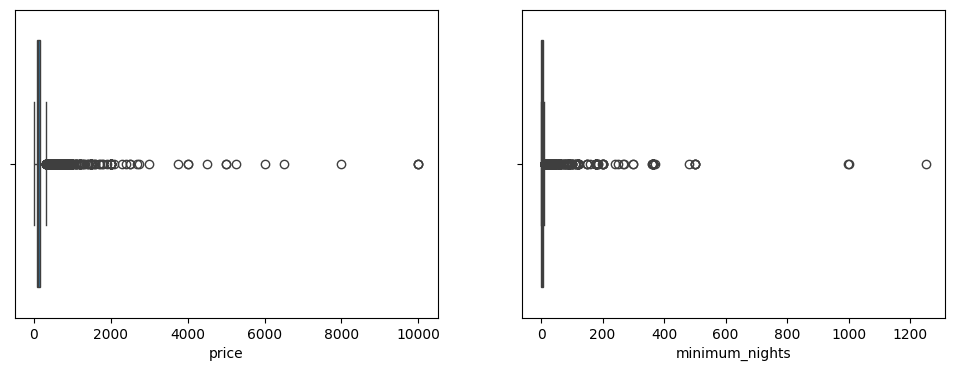

              price  minimum_nights
count  14883.000000    14883.000000
mean     155.733118        7.485252
std      247.072148       25.980234
min       10.000000        1.000000
25%       75.000000        1.000000
50%      117.000000        3.000000
75%      176.000000        5.000000
max    10000.000000     1250.000000


In [27]:
#outliers
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=df['price'], ax=ax[0])
sns.boxplot(x=df['minimum_nights'], ax=ax[1])
plt.show()

print(df[['price', 'minimum_nights']].describe())

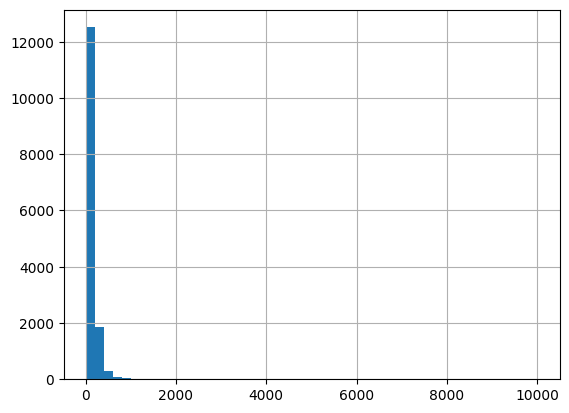

In [28]:
#histogram
df['price'].hist(bins=50)
plt.show()

In [29]:
#95% cutoffs
price_cap = df['price'].quantile(0.95)
nights_cap = df['minimum_nights'].quantile(0.95)
print(price_cap, nights_cap)

350.0 30.0


In [31]:
#remove outliers
print("Before:", df.shape)
df = df[(df['price'] > 0) & (df['price'] <= price_cap) & (df['minimum_nights'] <= nights_cap)]
print("After:", df.shape)

Before: (14883, 11)
After: (13959, 11)


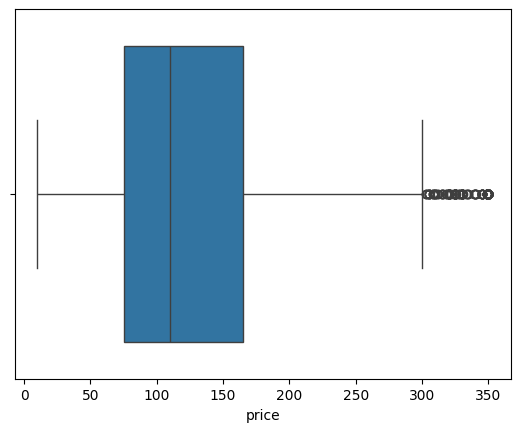

In [32]:
sns.boxplot(x=df['price'])
plt.show()

In [33]:
#count unique value
print(df['neighbourhood'].nunique())        # 200+
print(df['neighbourhood_group'].nunique())  # 5
print(df['neighbourhood_group'].unique())

186
5
['Brooklyn' 'Manhattan' 'Queens' 'Staten Island' 'Bronx']


In [34]:
#drop hyper specific column
df = df.drop('neighbourhood', axis=1)

In [35]:
#encode
df = pd.get_dummies(df, columns=['neighbourhood_group', 'room_type'],
                    drop_first=True, dtype=int)
print(df.shape)
df.head()

(13959, 14)


,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,neighbourhood_group_Brooklyn,neighbourhood_group_Manhattan,neighbourhood_group_Queens,neighbourhood_group_Staten Island,room_type_Private room,room_type_Shared room
0,40.64749,-73.97237,149.0,1.0,9.0,0.21,6.0,365.0,1,0,0,0,1,0
1,40.75362,-73.98377,225.0,1.0,45.0,0.38,2.0,355.0,0,1,0,0,0,0
2,40.80902,-73.94190,150.0,3.0,0.0,0.00,1.0,365.0,0,1,0,0,1,0
3,40.68514,-73.95976,89.0,1.0,270.0,4.64,1.0,194.0,1,0,0,0,0,0
4,40.79851,-73.94399,80.0,10.0,9.0,0.10,1.0,0.0,0,1,0,0,0,0


In [37]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 13959 entries, 0 to 14882
Data columns (total 14 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   latitude                           13959 non-null  float64
 1   longitude                          13959 non-null  float64
 2   price                              13959 non-null  float64
 3   minimum_nights                     13959 non-null  float64
 4   number_of_reviews                  13959 non-null  float64
 5   reviews_per_month                  13959 non-null  float64
 6   calculated_host_listings_count     13959 non-null  float64
 7   availability_365                   13959 non-null  float64
 8   neighbourhood_group_Brooklyn       13959 non-null  int64  
 9   neighbourhood_group_Manhattan      13959 non-null  int64  
 10  neighbourhood_group_Queens         13959 non-null  int64  
 11  neighbourhood_group_Staten Island  13959 non-null  int64  


In [38]:
#separate x and y
X = df.drop('price', axis=1)   # features: everything except price
y = df['price']                # target: what we want to predict

print(X.shape)
print(y.shape)

(13959, 13)
(13959,)


In [39]:
#train/test
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Train:", X_train.shape)
print("Test: ", X_test.shape)

Train: (11167, 13)
Test:  (2792, 13)


In [40]:
# train
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [41]:
#predict
y_pred = model.predict(X_test)

In [43]:
#metrics
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print(f"R² Score: {r2:.3f}")
print(f"MAE:  ${mae:.2f}")
print(f"MSE:  {mse:.2f}")
print(f"RMSE: ${rmse:.2f}")

R² Score: 0.451
MAE:  $37.45
MSE:  2593.31
RMSE: $50.92


In [44]:
#what model learned
coef = pd.DataFrame({'Feature': X.columns, 'Coefficient': model.coef_})
print(coef.sort_values('Coefficient', ascending=False))

                              Feature  Coefficient
8       neighbourhood_group_Manhattan    14.659025
9          neighbourhood_group_Queens     7.589956
4                   reviews_per_month     0.160460
5      calculated_host_listings_count     0.139047
6                    availability_365     0.066190
3                   number_of_reviews    -0.045610
2                      minimum_nights    -1.134502
7        neighbourhood_group_Brooklyn    -5.362013
0                            latitude   -32.994200
11             room_type_Private room   -76.354442
10  neighbourhood_group_Staten Island   -88.517467
12              room_type_Shared room   -91.079999
1                           longitude  -443.695031


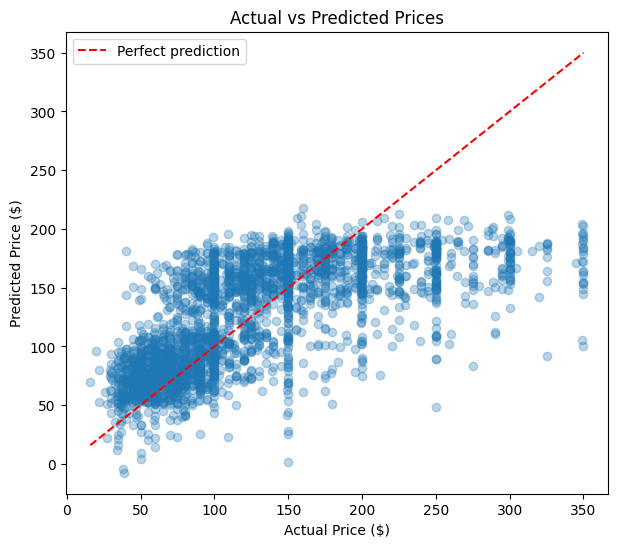

In [45]:
#Actual v/s predicted
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred, alpha=0.3)
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()], 'r--', label='Perfect prediction')
plt.xlabel('Actual Price ($)')
plt.ylabel('Predicted Price ($)')
plt.title('Actual vs Predicted Prices')
plt.legend()
plt.show()

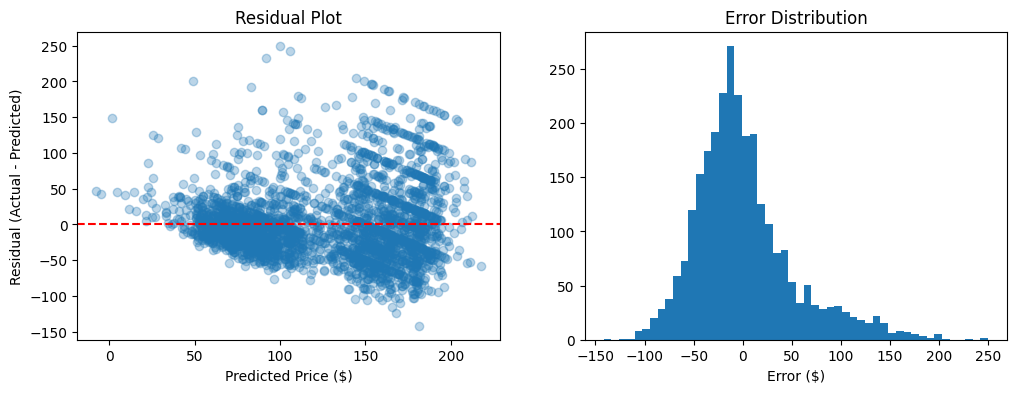

In [46]:
#residual plot and error histogram
residuals = y_test - y_pred

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].scatter(y_pred, residuals, alpha=0.3)
ax[0].axhline(0, color='r', linestyle='--')
ax[0].set_xlabel('Predicted Price ($)')
ax[0].set_ylabel('Residual (Actual - Predicted)')
ax[0].set_title('Residual Plot')

ax[1].hist(residuals, bins=50)
ax[1].set_xlabel('Error ($)')
ax[1].set_title('Error Distribution')

plt.show()

In [47]:
#check it with number
# Error for cheap vs expensive listings
cheap = y_test < y_test.median()
print("MAE (cheap): ", mean_absolute_error(y_test[cheap], y_pred[cheap]))
print("MAE (expensive):", mean_absolute_error(y_test[~cheap], y_pred[~cheap]))

MAE (cheap):  28.99423601579244
MAE (expensive): 45.84974705070329
